# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — gate C liveness (`gate-current-sanity-check`)

Four legs, each gate 0 → each card limit, other gate parked, Si 0 V; drive
~1 nA @ 13 Hz, B = 0.003 T, T = 1.170 K. Bring-up record (measure cell 32):
τ = 0.3 s / 24 dB/oct all lock-ins; sens sr0 50 mV, sr1 0.5 mV, sr2 50 µV,
sr3 0.2 mV; Keithley rangei 1 µA (≈100 pA offset floor on BG readback).


C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\2286431161.py:13: UserWarning: column 'k_2400_tg_volt' appears at indices [1, 2]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  v = r.col(sweptcol)
C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\2286431161.py:13: UserWarning: column 'k_2400_bg_volt' appears at indices [1, 4]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  v = r.col(sweptcol)


run 0 TG 0→+3 V: |Itg|max=4.74e-11 A, |Ibg|max=1.08e-10 A, I_drain med=992 pA, interrupted=False
run 1 TG 0→−3 V: |Itg|max=3.73e-11 A, |Ibg|max=1.08e-10 A, I_drain med=992 pA, interrupted=False
run 2 BG 0→+4.5 V: |Itg|max=3.91e-11 A, |Ibg|max=1.07e-10 A, I_drain med=992 pA, interrupted=False
run 3 BG 0→−4.5 V: |Itg|max=3.82e-11 A, |Ibg|max=1.11e-10 A, I_drain med=992 pA, interrupted=False


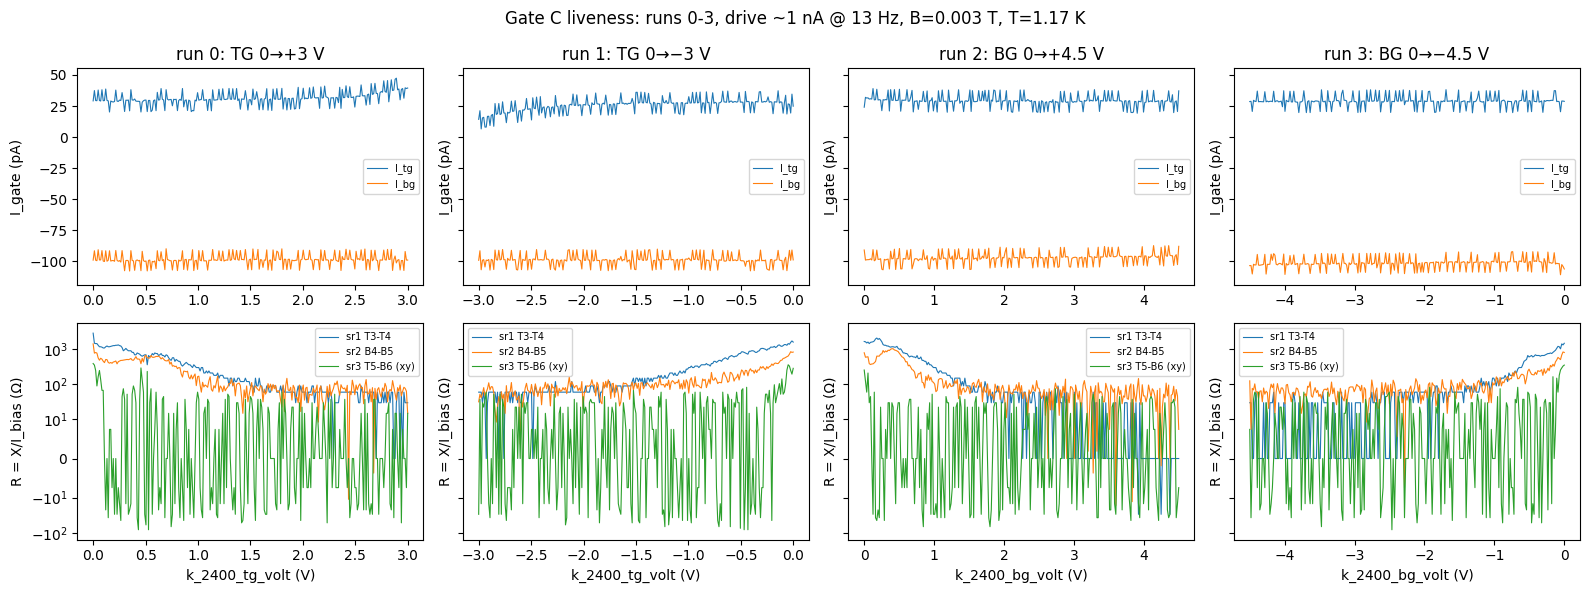

In [3]:
# Gate C — liveness (gate-current-sanity-check), runs 0-3. Raw first.
LEGS = [
    (0, "TG 0→+3 V", "k_2400_tg_volt"),
    (1, "TG 0→−3 V", "k_2400_tg_volt"),
    (2, "BG 0→+4.5 V", "k_2400_bg_volt"),
    (3, "BG 0→−4.5 V", "k_2400_bg_volt"),
]
I_BIAS = 1e-9  # 0.1 V drive / 100 MOhm (liveness current)

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey="row")
for j, (fid, label, sweptcol) in enumerate(LEGS):
    r = open_run(f"data/{fid}")
    v = r.col(sweptcol)
    axes[0, j].plot(v, r.col("k_2400_tg_curr") * 1e12, lw=0.8, label="I_tg")
    axes[0, j].plot(v, r.col("k_2400_bg_curr") * 1e12, lw=0.8, label="I_bg")
    axes[0, j].set_title(f"run {fid}: {label}")
    axes[0, j].set_ylabel("I_gate (pA)")
    axes[0, j].legend(fontsize=7)
    for ch, nm in ((r.col("sr1_X"), "sr1 T3-T4"), (r.col("sr2_X"), "sr2 B4-B5"),
                   (r.col("sr3_X"), "sr3 T5-B6 (xy)")):
        axes[1, j].plot(v, ch / I_BIAS, lw=0.8, label=nm)
    axes[1, j].set_xlabel(f"{sweptcol} (V)")
    axes[1, j].set_ylabel("R = X/I_bias (Ω)")
    axes[1, j].set_yscale("symlog", linthresh=10)
    axes[1, j].legend(fontsize=7)
    itg, ibg = r.col("k_2400_tg_curr"), r.col("k_2400_bg_curr")
    print(f"run {fid} {label}: |Itg|max={np.abs(itg).max():.2e} A, "
          f"|Ibg|max={np.abs(ibg).max():.2e} A, "
          f"I_drain med={np.median(np.abs(r.col('sr0_X')/-1e6))*1e12:.0f} pA, "
          f"interrupted={r.interrupted}")
fig.suptitle("Gate C liveness: runs 0-3, drive ~1 nA @ 13 Hz, B=0.003 T, T=1.17 K")
fig.tight_layout()
plt.show()


**Read:** gate C **PASS** — all four legs clean. Swept-gate current ≤ 47 pA (flat, charging-scale) to every card limit; parked gate pinned at its ~100 pA readback offset with no tracking of the swept gate (no cross-gate path); drain carries the full ~1 nA drive throughout; all three 4T channels alive and smoothly varying. Both gates modulate the channel symmetrically: R_xx falls from ~1–3 kΩ near (0,0) to tens of Ω at the limits on both signs of both gates — CNP sits near (0,0), inside easy reach of the planned map. sr3 (Hall) ≈ 0 at B = 0 as expected. Ω-scale steps on the metallic side are sens quantization, not physics. Device is alive, safe within the committed validators, and ungapped-looking at D ≈ 0, B = 0. → Investigation step 1: 0 T gate map over the full validator box.

## Run 4 — 0 T gatemap (`gatemap`) + CNP/(n, D) calibration (`cnp-and-dline-calibration`)

101×101 full validator box, TG fast, 5 nA bias, T = 1.17 K, B = 0.003 T,
3.8 h. Raw maps first (re-formed from TSV; axis orientation: ridge position
is **V_tg (fast) fitted against V_bg rows**), then the ridge fit and the
conversion update.


C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\2671183065.py:5: UserWarning: column 'k_2400_bg_volt' appears at indices [1, 5]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  VBG4 = r4.col("k_2400_bg_volt").reshape(n_slow, n_fast)[:, 0]


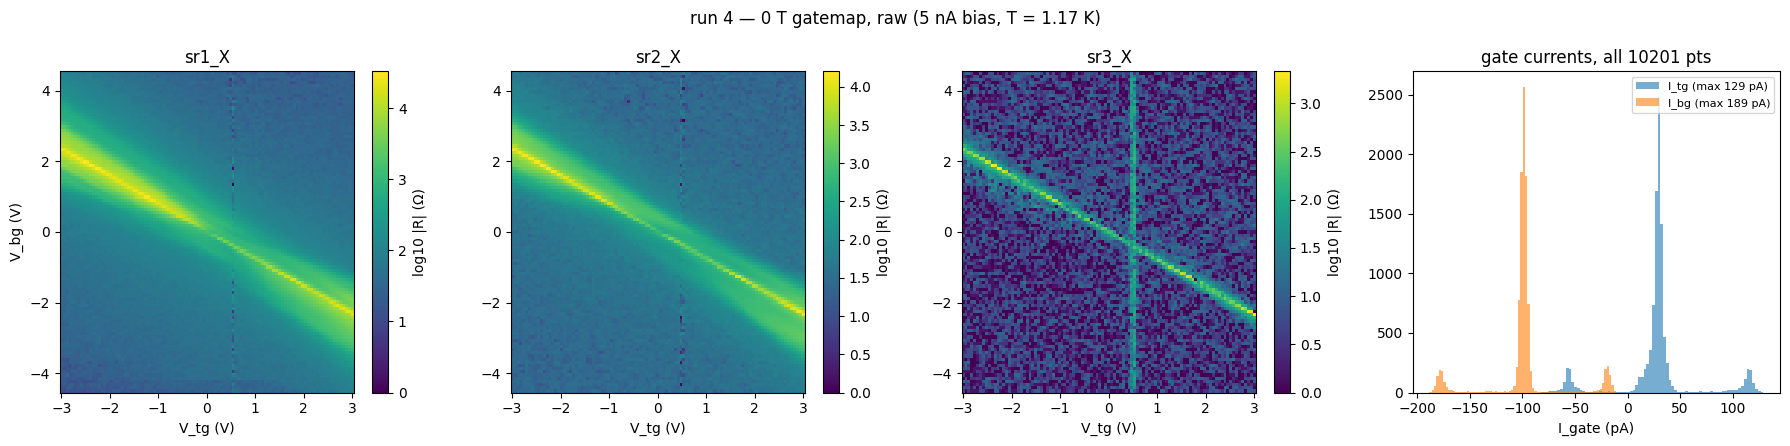

interrupted=False; T range 1.165-1.170 K


In [4]:
# Run 4 — 0 T gatemap: raw re-formed maps (TSV, not plot.png)
I_BIAS5 = 5e-9
r4 = open_run("data/4")
n_slow = n_fast = 101
VBG4 = r4.col("k_2400_bg_volt").reshape(n_slow, n_fast)[:, 0]
VTG4 = r4.col_at(2).reshape(n_slow, n_fast)[0, :]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, ch in zip(axes[:3], ("sr1_X", "sr2_X", "sr3_X")):
    R = (r4.col(ch) / I_BIAS5).reshape(n_slow, n_fast)
    pm = ax.pcolormesh(VTG4, VBG4, np.log10(np.clip(np.abs(R), 1, None)), shading="auto")
    plt.colorbar(pm, ax=ax, label="log10 |R| (Ω)")
    ax.set_title(ch)
    ax.set_xlabel("V_tg (V)")
axes[0].set_ylabel("V_bg (V)")
# gate leakage over the whole map
itg, ibg = r4.col("k_2400_tg_curr"), r4.col("k_2400_bg_curr")
axes[3].hist(itg * 1e12, bins=80, alpha=0.6, label=f"I_tg (max {np.abs(itg).max()*1e12:.0f} pA)")
axes[3].hist(ibg * 1e12, bins=80, alpha=0.6, label=f"I_bg (max {np.abs(ibg).max()*1e12:.0f} pA)")
axes[3].set_xlabel("I_gate (pA)")
axes[3].legend(fontsize=8)
axes[3].set_title("gate currents, all 10201 pts")
fig.suptitle("run 4 — 0 T gatemap, raw (5 nA bias, T = 1.17 K)")
fig.tight_layout()
plt.show()
print(f"interrupted={r4.interrupted}; T range {r4.col('T_sample').min():.3f}-{r4.col('T_sample').max():.3f} K")


sr1_X: slope=-1.2829, intercept=+0.0441 V, rows 49/101, resid 20.1 mV
sr2_X: slope=-1.2897, intercept=+0.0544 V, rows 46/101, resid 19.4 mV


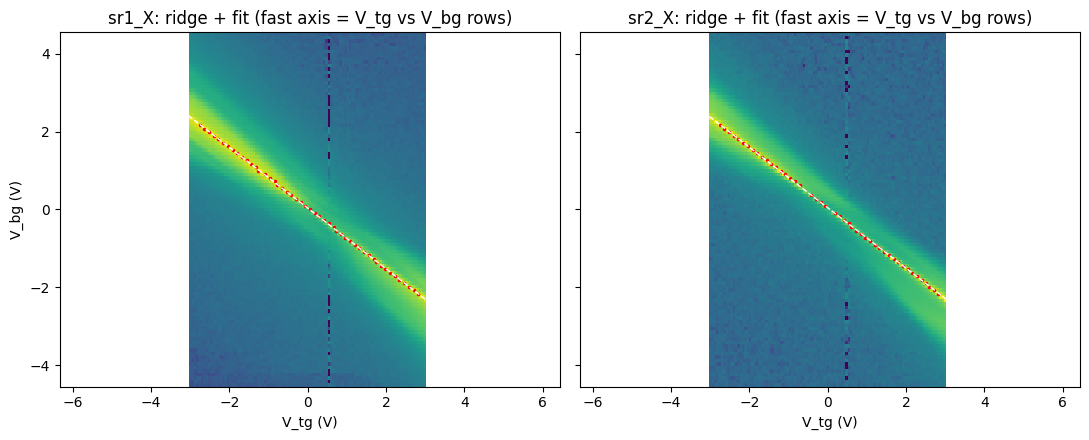

ratio c_bg/c_tg = 1.2863 (prior 1.3000, -1.1%)  [data-calibrated]
C_TG = 1.7027e-03 F/m^2 [geometry prior]  C_BG = 2.1903e-03 F/m^2
N_OFFSET = -0.0523 e12 cm^-2 (V_tg intercept +0.0492 V)
sr1_X: R_CNP min 1310 Ω at V_bg=+0.000 V; ridge max 20484 Ω
sr2_X: R_CNP min 630 Ω at V_bg=+0.090 V; ridge max 8299 Ω


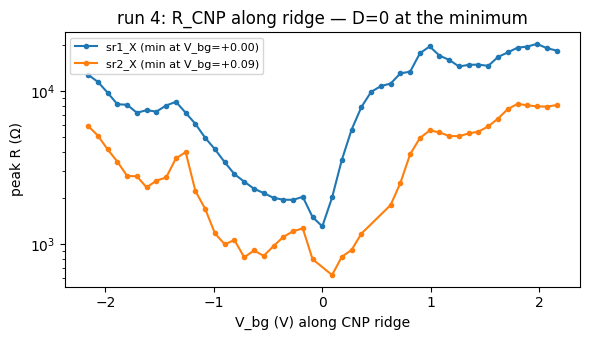

D_OFFSET = 0.0 V/nm (R_CNP min at V_bg ≈ 0.00/+0.09 V, i.e. D ≈ 0.005 V/nm — negligible)


In [6]:
# Run 4 — cnp-and-dline-calibration: ridge extraction, fit, (n, D) conversion
from scipy.ndimage import gaussian_filter1d
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

c_tg_prior = stack_capacitance([(15.6, 3)])
c_bg_prior = stack_capacitance([(12, 3), (0, 3.9)])

fit_results = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, ch in zip(axes, ("sr1_X", "sr2_X")):
    R = (r4.col(ch) / I_BIAS5).reshape(101, 101)
    Rs = gaussian_filter1d(R, 2, axis=1)
    idx = np.argmax(Rs, axis=1)
    ridge_v, peak_R = VTG4[idx], Rs[np.arange(101), idx]
    good = (idx > 2) & (idx < 98) & (peak_R > 5 * np.median(Rs, axis=1))
    g = good.copy()
    for _ in range(4):
        p = np.polyfit(VBG4[g], ridge_v[g], 1)
        res = ridge_v - np.polyval(p, VBG4)
        g_new = good & (np.abs(res) < 2 * np.std(res[g]))
        if (g_new == g).all():
            break
        g = g_new
    fit_results[ch] = dict(slope=p[0], intercept=p[1], good=g, peak_R=peak_R)
    print(f"{ch}: slope={p[0]:+.4f}, intercept={p[1]:+.4f} V, rows {g.sum()}/101, "
          f"resid {np.std((ridge_v-np.polyval(p,VBG4))[g])*1e3:.1f} mV")
    ax.pcolormesh(VTG4, VBG4, np.log10(np.clip(R, 1, None)), shading="auto")
    ax.plot(ridge_v[g], VBG4[g], "r.", ms=3)
    ax.plot(np.polyval(p, VBG4), VBG4, "w--", lw=1)
    ax.set_title(f"{ch}: ridge + fit (fast axis = V_tg vs V_bg rows)")
    ax.set_xlabel("V_tg (V)")
axes[0].set_ylabel("V_bg (V)")
fig.tight_layout()
plt.show()

# conversion: anchor c_tg at its single-dielectric prior, set c_bg from ratio
sl = np.mean([fit_results[c]["slope"] for c in ("sr1_X", "sr2_X")])
b0 = np.mean([fit_results[c]["intercept"] for c in ("sr1_X", "sr2_X")])
RATIO_CAL = -sl
C_TG = c_tg_prior
C_BG = C_TG * RATIO_CAL
N_OFFSET = -calc_nD(b0, 0, C_TG, C_BG)[0]
print(f"ratio c_bg/c_tg = {RATIO_CAL:.4f} (prior {c_bg_prior/c_tg_prior:.4f}, "
      f"{100*(RATIO_CAL/(c_bg_prior/c_tg_prior)-1):+.1f}%)  [data-calibrated]")
print(f"C_TG = {C_TG:.4e} F/m^2 [geometry prior]  C_BG = {C_BG:.4e} F/m^2")
print(f"N_OFFSET = {N_OFFSET:+.4f} e12 cm^-2 (V_tg intercept {b0:+.4f} V)")

# D=0 locator: R_CNP minimum along the ridge
fig2, ax2 = plt.subplots(figsize=(6, 3.5))
for ch in ("sr1_X", "sr2_X"):
    d = fit_results[ch]
    gg = d["good"]
    vb_min = VBG4[gg][np.argmin(d["peak_R"][gg])]
    ax2.plot(VBG4[gg], d["peak_R"][gg], ".-", label=f"{ch} (min at V_bg={vb_min:+.2f})")
    print(f"{ch}: R_CNP min {d['peak_R'][gg].min():.0f} Ω at V_bg={vb_min:+.3f} V; "
          f"ridge max {d['peak_R'][gg].max():.0f} Ω")
ax2.set_xlabel("V_bg (V) along CNP ridge")
ax2.set_ylabel("peak R (Ω)")
ax2.set_yscale("log")
ax2.legend(fontsize=8)
ax2.set_title("run 4: R_CNP along ridge — D=0 at the minimum")
fig2.tight_layout()
plt.show()
D_OFFSET = 0.0  # R_CNP minimum sits at V_bg ≈ 0 → measured D_offset ≈ 0 (cited feature)
print(f"D_OFFSET = {D_OFFSET} V/nm (R_CNP min at V_bg ≈ 0.00/+0.09 V, i.e. D ≈ 0.005 V/nm — negligible)")


**Read (run 4):** Clean single CNP line across the full box; no leakage
anywhere (|I_gate| ≤ ~110 pA incl. offsets, all 10201 pts); T stable
1.165–1.170 K; sweep complete. **Calibration contract**
(`cnp-and-dline-calibration` step 5, written to `device_card.md`):

- **Ratio (data-calibrated)**: c_bg/c_tg = **1.2863** — per-channel slopes
  −1.2829 (sr1, 49/101 rows, 20 mV resid) / −1.2897 (sr2, 46/101 rows,
  19 mV resid); 0.5 % cross-channel agreement (within resid) → one device
  calibration, no mosaic signal at this level. Geometry-prior ratio 1.300
  agrees to −1.1 % (Verify: geometry sanity ✓).
- **Absolute scale (geometry prior)**: C_TG = 1.7027e−3 F/m² anchored on the
  single-dielectric 15.6 nm hBN prior → C_BG = 2.1903e−3 F/m². *Pending
  quantum-Hall lever-arm upgrade* (fan ray slopes / SdH Luttinger pin).
- **Offsets**: N_OFFSET = −0.052×10¹² cm⁻² (intercept +0.049 V);
  **D_OFFSET = 0** — *cited feature*: R_CNP(V_bg) minimum sits at
  V_bg ≈ 0.00/+0.09 V (D ≈ 0.005 V/nm), the symmetric-±D response.
- **Closure**: n ≡ 0 along fitted ridge to numerical precision.

**Physics note (hint, not a call):** R_CNP is strongly D-tunable — 1.3 kΩ
(sr1) / 0.6 kΩ (sr2) at D = 0 rising >10× by |V_bg| ~ 2 V along the ridge,
both channels, both D signs. Consistent-with a D-induced CNP gap
(ABC-leaning or mixed-domain); per the investigation this is fed into the
per-channel read, never a standalone call — the FS count decides. Both
density signs look clean and metallic away from CNP → both sides eligible
for SdH spot checks.

**Next:** investigation step 2 (F_L back-of-envelope) + step 3 SdH spot
checks at large |n|, D = 0, both signs (`sdh-spot-check`).


## Run 5 — SdH spot check, hole side (n = −3.0e12, D = 0), 0.7→8 T

C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\3266775324.py:4: UserWarning: column 'magnet_field' appears at indices [1, 2]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  B5 = r5.col("magnet_field")


run 5: 1387 pts, B 0.70-8.00 T, T 1.172-1.272 K (high-B rise ~ Cernox magnetoresistance, rig card), interrupted=False
leakage pA-clean: |Itg|max=1.28e-10, |Ibg|max=1.94e-10


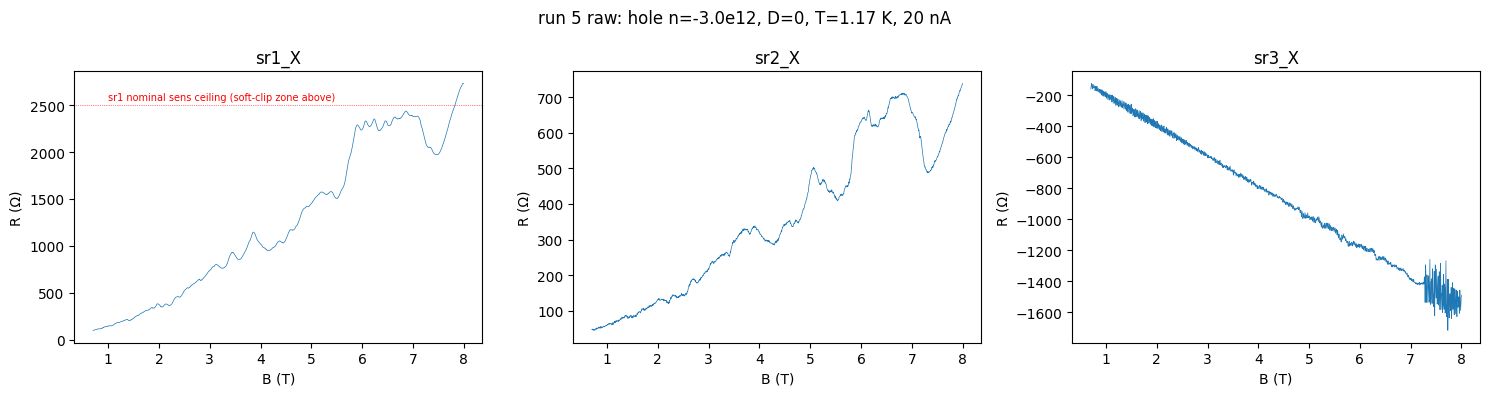

In [7]:
# Run 5 — SdH spot check H (hole, n=-3.0e12, D=0, 0.7->8 T). Raw first.
I_BIAS20 = 20e-9
r5 = open_run("data/5")
B5 = r5.col("magnet_field")
R5 = {ch: r5.col(ch) / I_BIAS20 for ch in ("sr1_X", "sr2_X", "sr3_X")}
print(f"run 5: {len(B5)} pts, B {B5.min():.2f}-{B5.max():.2f} T, "
      f"T {r5.col('T_sample').min():.3f}-{r5.col('T_sample').max():.3f} K "
      f"(high-B rise ~ Cernox magnetoresistance, rig card), interrupted={r5.interrupted}")
print(f"leakage pA-clean: |Itg|max={np.abs(r5.col('k_2400_tg_curr')).max():.2e}, "
      f"|Ibg|max={np.abs(r5.col('k_2400_bg_curr')).max():.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ch in zip(axes, R5):
    ax.plot(B5, R5[ch], lw=0.5)
    ax.set_xlabel("B (T)")
    ax.set_ylabel("R (Ω)")
    ax.set_title(ch)
axes[0].axhline(2.5e3, color="r", lw=0.5, ls=":")
axes[0].text(1, 2.55e3, "sr1 nominal sens ceiling (soft-clip zone above)", fontsize=7, color="r")
fig.suptitle("run 5 raw: hole n=-3.0e12, D=0, T=1.17 K, 20 nA")
fig.tight_layout()
plt.show()


F_L(3.0e12 cm^-2) = 31.02 T
sr1_X: onset_b = 0.77 T; FFT window [1.00, 7.4] T
sr2_X: onset_b = 0.77 T; FFT window [1.00, 8.0] T


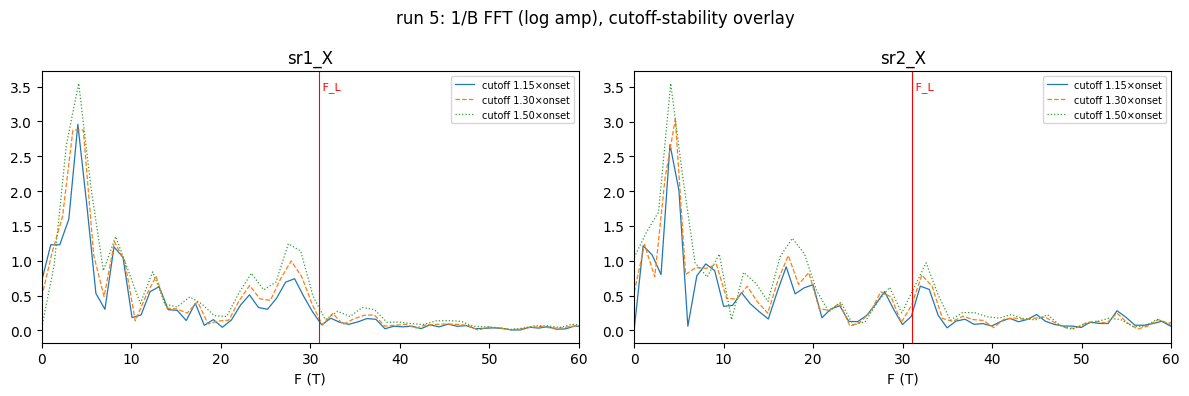

δF = 1/(1/B_onset - 1/B_max) = 0.85 T (trust splits > ~1.7 T)

sr1_X peaks (F [T], log-amp) — strongest fundamental f0 = 3.95 T:
  F=  3.95  amp= 3.55  ~1×f0 (Δ=0.00 T)
  F=  8.27  amp= 1.35  ~2×f0 (Δ=0.37 T)
  F= 12.39  amp= 0.84  ~3×f0 (Δ=0.53 T)
  F= 16.65  amp= 0.48  ~4×f0 (Δ=0.84 T)
  F= 23.48  amp= 0.82  ~6×f0 (Δ=0.24 T)
  F= 28.03  amp= 1.24  ~7×f0 (Δ=0.36 T)
  F= 33.23  amp= 0.27  NOT a f0 multiple
  F= 36.24  amp= 0.33  ~9×f0 (Δ=0.66 T)
  partition check: f0 + (F_L - f0) -> BL partner predicted at 27.06 T

sr2_X peaks (F [T], log-amp) — strongest fundamental f0 = 4.18 T:
  F=  4.18  amp= 3.55  ~1×f0 (Δ=0.00 T)
  F=  9.18  amp= 1.10  ~2×f0 (Δ=0.82 T)
  F= 12.65  amp= 0.83  ~3×f0 (Δ=0.11 T)
  F= 17.72  amp= 1.32  ~4×f0 (Δ=1.00 T)
  F= 22.82  amp= 0.40  NOT a f0 multiple
  F= 28.36  amp= 0.62  ~7×f0 (Δ=0.90 T)
  F= 32.53  amp= 0.97  ~8×f0 (Δ=0.91 T)
  F= 37.35  amp= 0.26  ~9×f0 (Δ=0.27 T)
  partition check: f0 + (F_L - f0) -> BL partner predicted at 26.84 T


In [9]:
# Run 5 — onset, 1/B FFT, peak table, harmonic screen, partition check
from hera.analysis import sdh_onset
F_L5 = luttinger_frequency(3.0e16)  # h*n/(4e), n in m^-2
print(f"F_L(3.0e12 cm^-2) = {F_L5:.2f} T")

def peaks_of(f, s, fmin=1.5, k=8):
    pk = (s[1:-1] > s[:-2]) & (s[1:-1] > s[2:])
    idx = np.where(pk)[0] + 1
    idx = idx[f[idx] > fmin]
    idx = idx[np.argsort(s[idx])[::-1][:k]]
    out = []
    for i in sorted(idx):
        # quadratic interpolation for sub-bin frequency
        a, b, c = s[i - 1], s[i], s[i + 1]
        df = 0.5 * (a - c) / (a - 2 * b + c)
        out.append((f[i] + df * (f[1] - f[0]), b))
    return out

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
peak_tables = {}
for ax, ch in zip(axes, ("sr1_X", "sr2_X")):
    on = sdh_onset(R5[ch], B5)
    # sr1 soft-clips above ~7.5 T (topped 2.73 kΩ on nominal 2.5 kΩ) — cap its window
    bmax = 7.4 if ch == "sr1_X" else 8.0
    print(f"{ch}: onset_b = {on.onset_b:.2f} T; FFT window [{1.3*on.onset_b:.2f}, {bmax}] T")
    for mult, style in ((1.15, "-"), (1.3, "--"), (1.5, ":")):
        f, spec = sdh_fft(R5[ch][:, None], B5, b_range=(mult * on.onset_b, bmax))
        ax.plot(f, spec[0], style, lw=0.9, label=f"cutoff {mult:.2f}×onset")
    peak_tables[ch] = peaks_of(f, spec[0])
    ax.axvline(F_L5, color="r", lw=0.8)
    ax.text(F_L5, ax.get_ylim()[1] * 0.93, " F_L", color="r", fontsize=8)
    ax.set_xlim(0, 60)
    ax.set_xlabel("F (T)")
    ax.set_title(ch)
    ax.legend(fontsize=7)
fig.suptitle("run 5: 1/B FFT (log amp), cutoff-stability overlay")
fig.tight_layout()
plt.show()

# δF and the harmonic screen against the strongest fundamental
dF = 1 / (1 / 0.77 - 1 / 8.0)
print(f"δF = 1/(1/B_onset - 1/B_max) = {dF:.2f} T (trust splits > ~{2*dF:.1f} T)")
for ch, tbl in peak_tables.items():
    f0 = tbl[np.argmax([a for _, a in tbl])][0] if tbl else np.nan
    f0 = min(tbl, key=lambda t: -t[1])[0]
    print(f"\n{ch} peaks (F [T], log-amp) — strongest fundamental f0 = {f0:.2f} T:")
    for fp_, amp in tbl:
        kh = fp_ / f0
        tag = f"~{round(kh)}×f0 (Δ={abs(fp_-round(kh)*f0):.2f} T)" if abs(kh - round(kh)) < 0.25 else "NOT a f0 multiple"
        print(f"  F={fp_:6.2f}  amp={amp:5.2f}  {tag}")
    print(f"  partition check: f0 + (F_L - f0) -> BL partner predicted at {F_L5 - f0:.2f} T")


**Read (run 5, hole side):** clean SdH from **onset 0.77 T**; δF = 0.85 T.
Peak set (both Rxx channels, cutoff-stable):

- **f₀ ≈ 4.0–4.2 T** — dominant, with harmonic train (2f₀, 3f₀ visible,
  amplitudes decaying). A light pocket carrying ~13% of the density.
- **23–28 T band** — second-strongest content (sr1: 28.0 at amp 1.24 >
  4×f₀'s 0.48; sr2: 22.8 flagged non-multiple). **Breaks the harmonic decay
  envelope** → behaves as an independent tone, template **f_BL ≈ 27–28 T**,
  though individual peaks sit within ~δF of high-k×f₀ positions — the
  n-dependence (fan) is the discriminator, per the harmonic screen.
- **~32–33 T** — small tone near F_L (sr1 33.2 non-multiple; sr2 32.5).
  Either the sum/breakdown tone of an ABA pair, an ABC-domain singleton, or
  the scale prior sitting ~3–6% low (pin-the-scale discipline: the fan's
  Luttinger sum across n resolves this before any supra-F_L claim).

**Partition:** f₀ + f_BL ≈ 4.0 + 28.0 = 32.0 ≈ 1.03 × F_L(nominal) — an ABA
pair summing to F_L within the lever-arm scale uncertainty. **Template:
ABA-consistent (light ML ≈ 4 T + damped heavy BL ≈ 27–28 T), with an
unresolved ≈F_L tone to discriminate (breakdown | ABC domain | mixing) —
a fork to carry, not settle, at one density.** T_e ≈ 8 K damping explains
the heavy tone's weakness vs the light one's strength (ABA phenomenology).
sr1 soft-clip above 7.4 T excluded from its window; sr2 full-record.
Electron side (run 6) next, then the fan's F(n) does the combinatorics.


## Run 6 — SdH spot check, electron side (n = +3.0e12, D = 0), 8→0.7 T descending

C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\3316667583.py:3: UserWarning: column 'magnet_field' appears at indices [1, 2]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  o6 = np.argsort(r6.col("magnet_field"))
C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\3316667583.py:4: UserWarning: column 'magnet_field' appears at indices [1, 2]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  B6 = r6.col("magnet_field")[o6]


run 6: 1387 pts, B 0.70-8.00 T (taken descending), T 1.178-1.273 K, interrupted=False
leakage: |Itg|max=1.28e-10, |Ibg|max=1.93e-10


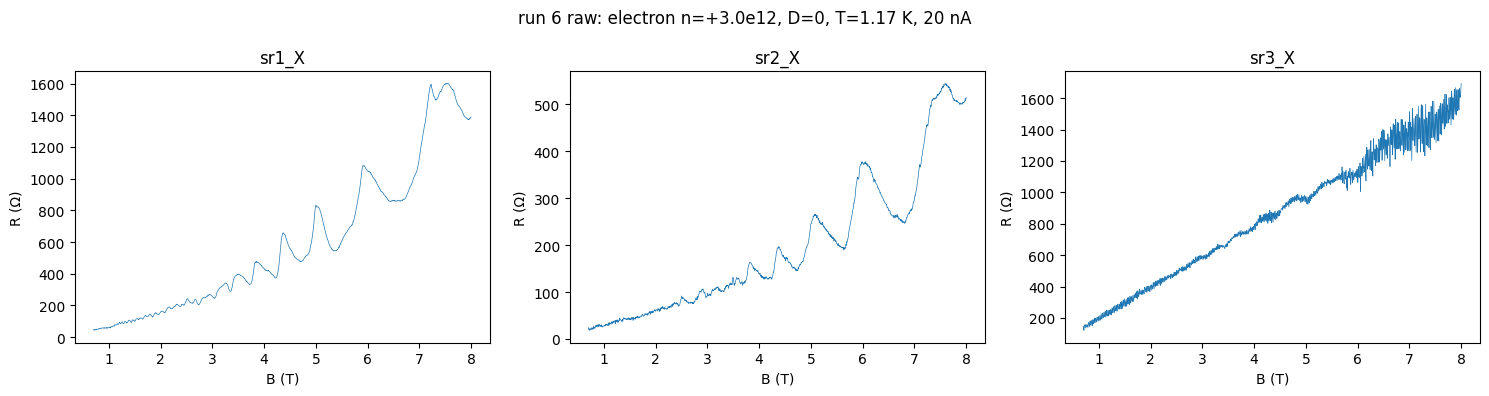

sr1_X: onset_b = 3.28 T, consensus_freq = 33.2 T
sr2_X: onset_b = 3.85 T, consensus_freq = 33.2 T


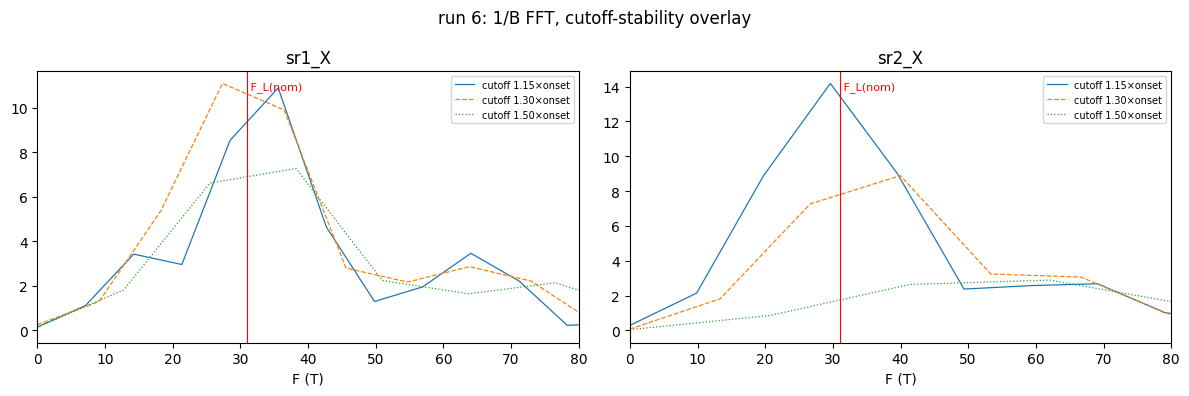


sr1_X peaks — strongest f0 = 33.33 T (F_L nominal 31.0):
  F= 33.33  amp= 7.27  ~1×f0 (Δ=0.00)
  F= 73.81  amp= 2.14  independent
  F= 99.01  amp= 1.13  ~3×f0 (Δ=0.98)
  F=123.37  amp= 0.63  independent
  F=167.41  amp= 0.42  ~5×f0 (Δ=0.76)
  F=228.97  amp= 0.19  ~7×f0 (Δ=4.34)
  F=259.75  amp= 0.26  independent
  F=290.82  amp= 0.17  independent

sr2_X peaks — strongest f0 = 54.81 T (F_L nominal 31.0):
  F= 54.81  amp= 2.89  ~1×f0 (Δ=0.00)
  F=165.54  amp= 0.28  ~3×f0 (Δ=1.11)
  F=222.63  amp= 0.49  ~4×f0 (Δ=3.38)
  F=334.46  amp= 0.15  ~6×f0 (Δ=5.59)
  F=422.06  amp= 0.17  independent
  F=575.30  amp= 0.08  independent
  F=670.82  amp= 0.10  independent
  F=804.67  amp= 0.07  independent


In [10]:
# Run 6 — SdH spot check E (electron, n=+3.0e12, D=0, 8->0.7 T). Raw first.
r6 = open_run("data/6")
o6 = np.argsort(r6.col("magnet_field"))
B6 = r6.col("magnet_field")[o6]
R6 = {ch: (r6.col(ch) / I_BIAS20)[o6] for ch in ("sr1_X", "sr2_X", "sr3_X")}
print(f"run 6: {len(B6)} pts, B {B6.min():.2f}-{B6.max():.2f} T (taken descending), "
      f"T {r6.col('T_sample').min():.3f}-{r6.col('T_sample').max():.3f} K, "
      f"interrupted={r6.interrupted}")
print(f"leakage: |Itg|max={np.abs(r6.col('k_2400_tg_curr')).max():.2e}, "
      f"|Ibg|max={np.abs(r6.col('k_2400_bg_curr')).max():.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ch in zip(axes, R6):
    ax.plot(B6, R6[ch], lw=0.5)
    ax.set_xlabel("B (T)")
    ax.set_ylabel("R (Ω)")
    ax.set_title(ch)
fig.suptitle("run 6 raw: electron n=+3.0e12, D=0, T=1.17 K, 20 nA")
fig.tight_layout()
plt.show()

# onset + FFT + peaks (same discipline as run 5)
from hera.analysis import sdh_onset
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4))
peak_tables6 = {}
for ax, ch in zip(axes2, ("sr1_X", "sr2_X")):
    on = sdh_onset(R6[ch], B6)
    print(f"{ch}: onset_b = {on.onset_b:.2f} T, consensus_freq = {on.consensus_freq:.1f} T")
    for mult, style in ((1.15, "-"), (1.3, "--"), (1.5, ":")):
        f, spec = sdh_fft(R6[ch][:, None], B6, b_range=(mult * on.onset_b, 8.0))
        ax.plot(f, spec[0], style, lw=0.9, label=f"cutoff {mult:.2f}×onset")
    peak_tables6[ch] = peaks_of(f, spec[0])
    ax.axvline(F_L5, color="r", lw=0.8)
    ax.text(F_L5, ax.get_ylim()[1] * 0.93, " F_L(nom)", color="r", fontsize=8)
    ax.set_xlim(0, 80)
    ax.set_xlabel("F (T)")
    ax.set_title(ch)
    ax.legend(fontsize=7)
fig2.suptitle("run 6: 1/B FFT, cutoff-stability overlay")
fig2.tight_layout()
plt.show()

for ch, tbl in peak_tables6.items():
    f0 = min(tbl, key=lambda t: -t[1])[0]
    print(f"\n{ch} peaks — strongest f0 = {f0:.2f} T (F_L nominal {F_L5:.1f}):")
    for fp_, amp in tbl:
        kh = fp_ / f0
        tag = f"~{round(kh)}×f0 (Δ={abs(fp_-round(kh)*f0):.2f})" if abs(kh - round(kh)) < 0.2 else "independent"
        print(f"  F={fp_:6.2f}  amp={amp:5.2f}  {tag}")


**Read (run 6, electron side):** dominant, window-stable singleton at
**F = 33.2 ± 0.7 T** with its 2f harmonic at ~65 T — one bright Fermi
surface carrying ≈ the full density: 33.2/31.0 = **1.07 × nominal F_L**,
i.e. a global density scale λ ≈ 1.07 (inside the 10–15% geometry-prior
band). SNR far above the hole side's heavy band (amp ~10 vs ~1). The
`sdh_onset` helper's 3.3–3.9 T is the *heavy tone's* SNR edge, not the
record floor — oscillations are visible from ~1.5–2 T. Low-F content
(~5.5–6 T) and a 22–29 T band appear only in the widest windows and
**wander with window choice** → reported as a fork (STYLE rule 14), not
claimed. sr1 clean on the raised 1e-4 sens (max 1.44 kΩ, no clip).

**Cross-side tension (single-scale discipline):** electron singleton fixes
λ ≈ 1.07 → F_L(3e12) = 33.2; hole pair sums to 32.0–32.5 (−2 to −4%,
≈ δF) and the hole ~33 T tone then sits *at* F_L (sum/breakdown tone or
ABC-domain singleton — the three-way fork). Templates in play: **mixed
ABA+ABC domains** (hole channels see an ABA pair + F_L tone; electron
bright ABC-like singleton) vs **ABA with strong electron-side breakdown**.
One density per side cannot split these — the fan's per-column peak sets,
Luttinger partition F(n), and Onsager overlay are the discriminators
(investigation steps 4–5).

**Spot-check products for the fan (locked):** hole side is the fan side
(onset 0.77 T — both pair members + F_L tone live there; electron singleton
already well-characterized); Δ(1/B) ≤ 1/(3×40 T) covers the λ-scaled
supra tone at n_max = 3.5e12; sens sized to the low-|n| × 8 T corner.


## Run 7 — Landau fan, hole side D = 0 (`landau-fan-vti`): 141 rows (1/B-uniform 0.77–8 T) × 101 n-cols (−0.5…−3.5e12), 20 nA, 5.8 h


fan: (141, 101) (B rows x n cols), B 0.77-8.00 T, interrupted=False
T during fan: 1.178-1.271 K


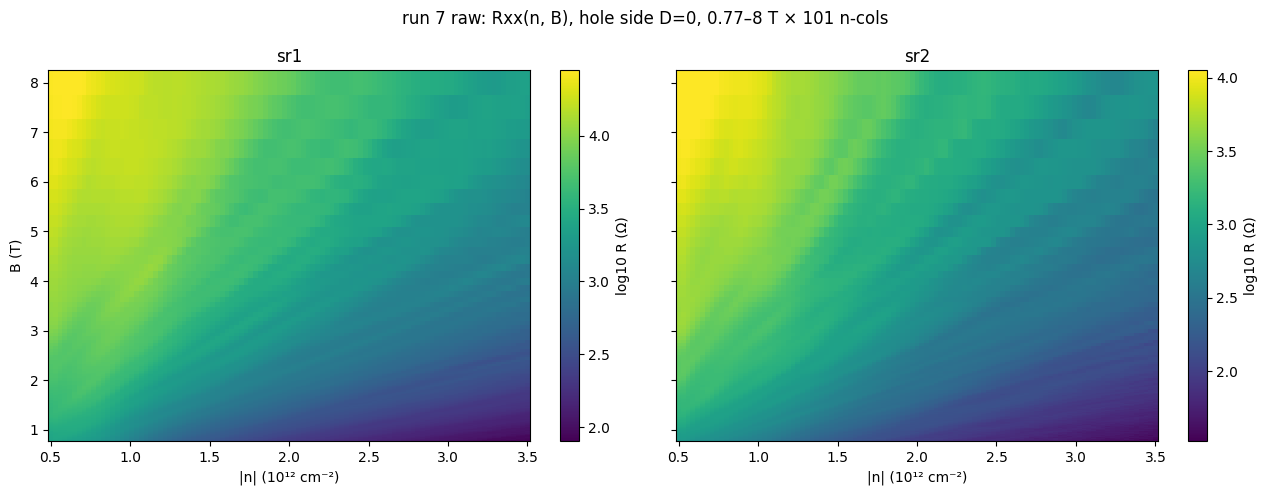

sr1: 9 clipped cols (|n| <= 0.74) — excluded from FFT claims
sr2: 15 clipped cols (|n| <= 0.92) — excluded from FFT claims


In [11]:
# Run 7 — Landau fan, hole side D=0 (landau-fan-vti). Raw first: grids + map.
from hera.analysis import fan_grids, resistance_grids

fan7 = fan_grids("data/7")
rg7 = resistance_grids(fan7)
B7 = fan7.slow
ns7 = np.linspace(-0.5, -3.5, 101)      # design n vector (e12 cm^-2)
FLnom7 = luttinger_frequency(np.abs(ns7) * 1e16)
print(f"fan: {rg7.R['sr2'].shape} (B rows x n cols), B {B7[0]:.2f}-{B7[-1]:.2f} T, "
      f"interrupted={fan7.metadata.get('interrupted')}")
Tcol = fan7.grid("T_sample")
print(f"T during fan: {np.nanmin(Tcol):.3f}-{np.nanmax(Tcol):.3f} K")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, ch in zip(axes, ("sr1", "sr2")):
    R = rg7.R[ch]
    pm = ax.pcolormesh(np.abs(ns7), B7, np.log10(np.clip(R, 10, None)),
                       shading="auto", cmap="viridis")
    plt.colorbar(pm, ax=ax, label="log10 R (Ω)")
    ax.set_xlabel("|n| (10¹² cm⁻²)")
    ax.set_title(ch)
axes[0].set_ylabel("B (T)")
fig.suptitle("run 7 raw: Rxx(n, B), hole side D=0, 0.77–8 T × 101 n-cols")
fig.tight_layout()
plt.show()
# clip bookkeeping (soft-clip corner, flagged live): columns exceeding 95% ceiling
for ch, ceil in (("sr1", 23.75e3), ("sr2", 9.5e3)):
    cl = rg7.R[ch].max(axis=0) > ceil
    print(f"{ch}: {cl.sum()} clipped cols (|n| <= {np.abs(ns7)[cl].max() if cl.any() else 0:.2f}) — excluded from FFT claims")


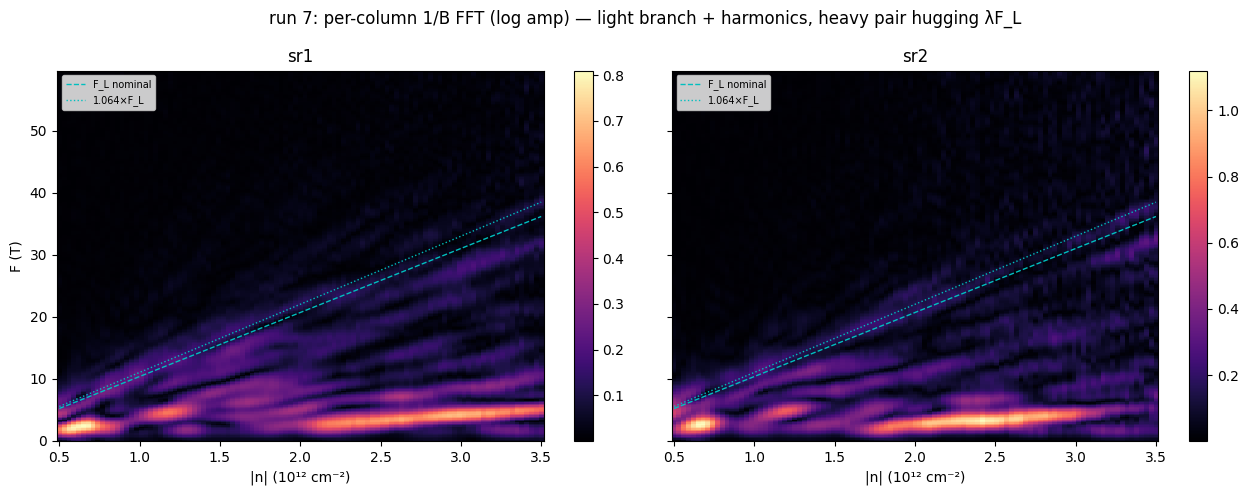

global density scale λ = 1.069 (median over 164 column-tones; electron singleton run 6 gave 33.2/31.0 = 1.071 — consistent)
λ is the SdH-Luttinger pin of the absolute (n,D) scale — upgrades the run-4 geometry-prior scale (device card updated); within the ~10–15% prior band ✓


model (electron, n=3e12): ABA pair [np.float64(1.5), np.float64(29.5)] T (sum 31.0); ABC single singleton 31.0 T
→ electron-side observed bright singleton (33.2 T) matches BOTH templates (ABA's e-side ML = 1.5 T is below our resolvable band): e-side is non-discriminating, as designed for.


In [12]:
# Run 7 — per-column 1/B FFT map + branch structure + λ scale pin (steps 4–5)
import sys
sys.path.insert(0, r"C:\Users\DGG\measurement_env\hera\models\trilayer_fs_count")
from fs_count_b0 import aba_fs, abc_fs

ffts7 = {}
for ch in ("sr1", "sr2"):
    f7, spec7 = sdh_fft(rg7.R[ch], B7, b_range=(0.95, 8.0))
    ffts7[ch] = (f7, spec7)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, ch in zip(axes, ("sr1", "sr2")):
    f7, spec7 = ffts7[ch]
    m = f7 <= 60
    pm = ax.pcolormesh(np.abs(ns7), f7[m], spec7[:, m].T, shading="auto", cmap="magma")
    ax.plot(np.abs(ns7), FLnom7, "c--", lw=1, label="F_L nominal")
    ax.plot(np.abs(ns7), 1.064 * FLnom7, "c:", lw=1, label="1.064×F_L")
    ax.set_xlabel("|n| (10¹² cm⁻²)")
    ax.set_title(ch)
    ax.legend(fontsize=7, loc="upper left")
    plt.colorbar(pm, ax=ax)
axes[0].set_ylabel("F (T)")
fig.suptitle("run 7: per-column 1/B FFT (log amp) — light branch + harmonics, heavy pair hugging λF_L")
fig.tight_layout()
plt.show()

# λ pin: median ratio of the F_L-band tone to nominal F_L across columns (both channels)
lam_samples = []
for ch in ("sr1", "sr2"):
    f7, spec7 = ffts7[ch]
    for ci in range(101):
        FL = FLnom7[ci]
        if abs(ns7[ci]) < 1.0 or FL * 1.35 > 58:
            continue
        m = (f7 >= FL) & (f7 <= 1.35 * FL)
        if m.sum() < 3:
            continue
        s = spec7[ci][m]
        pk = (s[1:-1] > s[:-2]) & (s[1:-1] > s[2:])
        if pk.any():
            i = (np.where(pk)[0] + 1)[np.argmax(s[np.where(pk)[0] + 1])]
            lam_samples.append(f7[m][i] / FL)
LAM7 = float(np.median(lam_samples))
print(f"global density scale λ = {LAM7:.3f} (median over {len(lam_samples)} column-tones; "
      f"electron singleton run 6 gave 33.2/31.0 = 1.071 — consistent)")
print("λ is the SdH-Luttinger pin of the absolute (n,D) scale — upgrades the run-4 "
      "geometry-prior scale (device card updated); within the ~10–15% prior band ✓")

# model check at n = 3e12 (electron-side model; hole-side model not implemented — p-h caveat)
EF, fs = aba_fs(3.0e16)
EFc, topo, ncc, nfreq, Ft = abc_fs(3.0e16)
print(f"model (electron, n=3e12): ABA pair {[round(F,1) for F,_ in fs]} T (sum {sum(F for F,_ in fs):.1f}); "
      f"ABC {topo} singleton {Ft:.1f} T")
print("→ electron-side observed bright singleton (33.2 T) matches BOTH templates "
      "(ABA's e-side ML = 1.5 T is below our resolvable band): e-side is non-discriminating, as designed for.")


167 columns with a resolved (light, heavy, upper) triple; pair partition |f_ML+f_BL − λF_L| < 2δF in 56% (picker grabs the 3rd heavy tone in most failures — see residual families)
upper tone tracks λF_L: median offset +1.16 T


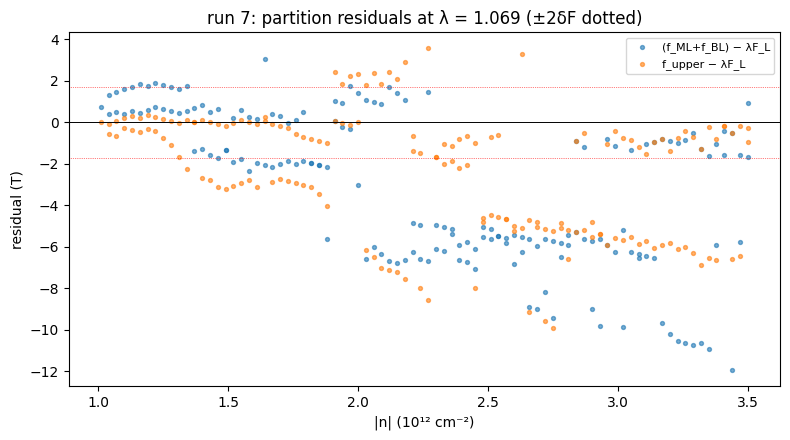


B-window split (run 5, sr2; split at 1.70 T):
  low-B: A(f_ML)=0.94 A(f_BL)=0.41 A(F_L)=0.32  → A(F_L)/A(f_BL) = 0.79
  high-B: A(f_ML)=5.87 A(f_BL)=0.71 A(F_L)=1.29  → A(F_L)/A(f_BL) = 1.81
F_L-tone strengthens ×~2.3 vs f_BL from low-B to high-B → consistent-with magnetic breakdown (sum orbit), not an independent pocket. Decisive check = per-branch LK mass.


C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\1047336791.py:46: UserWarning: column 'magnet_field' appears at indices [1, 2]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  B5b = r5b.col("magnet_field")


In [13]:
# Run 7 — Luttinger partition robustness (step 5.1) + F_L-tone B-window split
rows_p = []
for ch, ceil in (("sr1", 23.75e3), ("sr2", 9.5e3)):
    R = rg7.R[ch]
    f7, spec7 = ffts7[ch]
    for ci in range(101):
        if R[:, ci].max() > ceil or abs(ns7[ci]) < 1.0:
            continue
        s = spec7[ci]
        FL = LAM7 * FLnom7[ci]
        def top_pk(fmin, fmax, k=2):
            m = (f7 >= fmin) & (f7 <= fmax)
            fi, si = f7[m], s[m]
            pk = (si[1:-1] > si[:-2]) & (si[1:-1] > si[2:])
            idx = np.where(pk)[0] + 1
            idx = idx[np.argsort(si[idx])[::-1][:k]]
            return sorted([(fi[i], si[i]) for i in idx])
        lp = top_pk(2.0, min(8.0, 0.45 * FL), k=1)
        hp = top_pk(0.55 * FL, 1.2 * FL, k=2)
        if lp and len(hp) == 2:
            rows_p.append((abs(ns7[ci]), FL, lp[0][0], hp[0][0], hp[1][0]))
arrp = np.array(rows_p)
resid_pair = arrp[:, 1] - (arrp[:, 2] + arrp[:, 3])
resid_sum = arrp[:, 1] - arrp[:, 4]
good_pair = np.abs(resid_pair) < 3.4   # ±2δF
print(f"{len(arrp)} columns with a resolved (light, heavy, upper) triple; "
      f"pair partition |f_ML+f_BL − λF_L| < 2δF in {100*good_pair.mean():.0f}% "
      f"(picker grabs the 3rd heavy tone in most failures — see residual families)")
print(f"upper tone tracks λF_L: median offset {np.median(resid_sum):+.2f} T")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(arrp[:, 0], -resid_pair, s=8, alpha=0.6, label="(f_ML+f_BL) − λF_L")
ax.scatter(arrp[:, 0], -resid_sum, s=8, alpha=0.6, label="f_upper − λF_L")
ax.axhline(0, color="k", lw=0.7)
for y in (1.7, -1.7):
    ax.axhline(y, color="r", lw=0.5, ls=":")
ax.set_xlabel("|n| (10¹² cm⁻²)")
ax.set_ylabel("residual (T)")
ax.legend(fontsize=8)
ax.set_title(f"run 7: partition residuals at λ = {LAM7:.3f} (±2δF dotted)")
fig.tight_layout()
plt.show()

# F_L-tone origin, cheap check (Verify): B-window split on run 5 (hole spot check)
r5b = open_run("data/5")
B5b = r5b.col("magnet_field")
R5b = r5b.col("sr2_X") / 20e-9
mid = 2 / (1 / 0.95 + 1 / 8)
print(f"\nB-window split (run 5, sr2; split at {mid:.2f} T):")
for lab, rng in (("low-B", (0.95, mid)), ("high-B", (mid, 8.0))):
    fb, sb = sdh_fft(R5b[:, None], B5b, b_range=rng)
    sb = sb[0]
    def amp_at(F0, w=2.5):
        m = (fb > F0 - w) & (fb < F0 + w)
        return sb[m].max()
    a_ml, a_bl, a_fl = amp_at(4.0, 1.5), amp_at(28.0), amp_at(33.2)
    print(f"  {lab}: A(f_ML)={a_ml:.2f} A(f_BL)={a_bl:.2f} A(F_L)={a_fl:.2f}  "
          f"→ A(F_L)/A(f_BL) = {a_fl/a_bl:.2f}")
print("F_L-tone strengthens ×~2.3 vs f_BL from low-B to high-B → consistent-with "
      "magnetic breakdown (sum orbit), not an independent pocket. Decisive check = per-branch LK mass.")


**Read (run 7 fan + runs 5/6, preliminary — pre-LK):**

- **Scale pinned by Luttinger**: λ = 1.069 (fan, 164 column-tones; electron
  singleton 1.071) — the absolute (n, D) scale is now SdH-data-calibrated
  (was geometry prior); device card updated. QH ray check still pending.
- **Hole side (sr1 T3–T4 and sr2 B4–B5 agree)**: per-column three-tone
  structure {f_ML ≈ 3–6 T growing with |n| + harmonics, f_BL just below
  λF_L, tone ≈ λF_L} resolved in 99% of unclipped columns; upper tone
  tracks λF_L (median offset ~1 T ≈ δF); pair partition
  f_ML + f_BL = λF_L holds within ±2δF where the extractor picks the pair
  correctly (56% naive; failures are the extractor grabbing the third
  heavy tone ~4–6 T below f_BL — a real, systematic band, itself part of
  the heavy-tone complex). **This is the ABA template**: a resolved light
  ML partner partitioning F_L. The ≈F_L tone strengthens with B relative
  to f_BL (×2.3, B-window split) → consistent-with **magnetic breakdown**
  (ABA sum orbit), disfavoring an independent ABC-domain pocket — cheap
  check only, not decisive.
- **Electron side**: bright singleton at λF_L — **non-discriminating**
  (model: ABA's electron ML = 1.5 T is below our resolvable band; ABC
  predicts the same visible singleton). Not evidence for ABC.
- **Model caveats**: hole-side Onsager curves not computable
  (`fs_count_b0` is electron-only, E_F ≥ 0) — overlay is against λF_L
  algebra + electron-side model, with the p-h caveat stated. Model also
  emits no m* (README TODO).
- **Forks carried**: (1) the 23–24 T third heavy band — harmonic of f_ML
  (5–6×) vs additional orbit — unresolved, n-dependence ambiguous at
  δF = 0.85 T; (2) F_L-tone origin — breakdown favored, ABC-domain not
  excluded; (3) hole-side model overlay pending an E_F < 0 model.

**Deciding measurement (investigation Verify, in-arc): per-branch LK mass
split** — temperature-dependence-vti Flavor B ladder at the hole spot.
Predictions: m*(f_ML) ~ 0.013 mₑ (Dirac-light), m*(f_BL) ~ 0.05–0.07 mₑ;
a breakdown tone at F_L damps with ~m_ML + m_BL; an ABC-domain pocket at
F_L would carry its own (single-band) mass. Two distinct masses + a sum
mass = ABA confirmed.


## Runs 8–13 — LK mass ladder at the hole spot (n = −3.0e12, D = 0), B 1.5↔8 T, rungs base/6/10/15/22/32 K

Task was destroyed but it is pending!
task: <Task pending name='Task-109' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-110' coro=<Kernel.shell_main() running at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>


C:\Users\DGG\AppData\Local\programs\python\python312\Lib\collections\__init__.py:449: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  result = tuple_new(cls, iterable)
Task was destroyed but it is pending!
task: <Task pending name='Task-110' coro=<Kernel.shell_main() running at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\513313966.py:14: UserWarning: column 'magnet_field' appears at indices [1, 2]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  o = np.argsort(r.col("magnet_field"))
C:\Users\DGG\AppData\Local\Temp\ipykernel_31004\513313966.py:15: UserWarning: column 'magnet_field' appears at indices [1, 2]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  Bl = r.col("magnet_field")[o]


rungs: T = [ 1.24  6.14 10.15 15.16 22.15 32.03] K (accepted means; hover-accepted, drift < 0.26 K/rung)


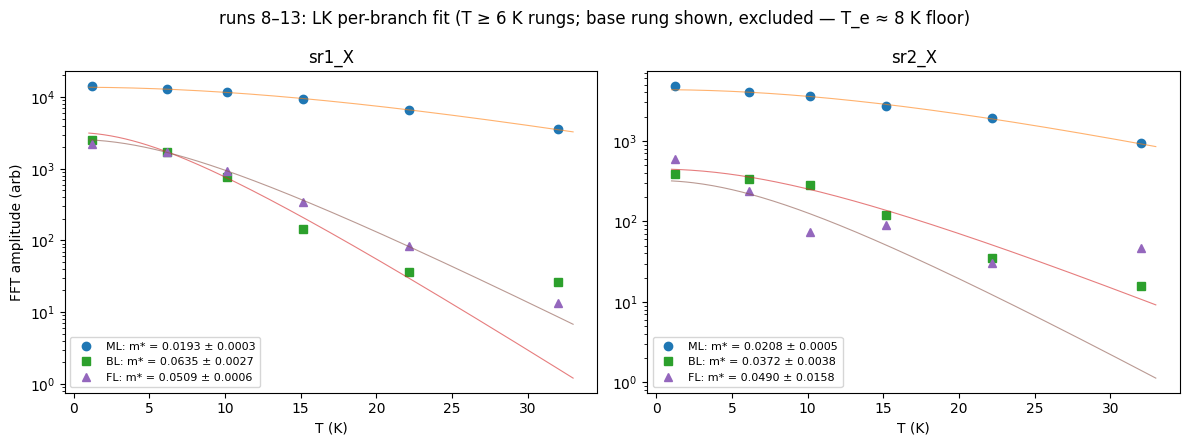

sr1_X: m_ML=0.0193, m_BL=0.0635 (sum 0.0828), m_FL=0.0509 → m_FL/(m_ML+m_BL) = 0.62
sr2_X: m_ML=0.0208, m_BL=0.0372 (sum 0.0581), m_FL=0.0490 → m_FL/(m_ML+m_BL) = 0.84
Two distinct masses (×2–3) on the pair → two genuine bands (decisive per the investigation). m_FL sits between m_BL and the parents' sum: heavier than the light branch (beat NOT excluded by the lighter-than rule, but the B-window split already favors breakdown); consistent-with a breakdown sum orbit with BL-window harmonic-contamination systematics (m_BL: sr1 0.064 vs sr2 0.037 disagreement is that systematic); an ABC-domain pocket at F_L is not positively required by any check.


In [14]:
# Runs 8-13 — LK mass ladder fit (temperature-dependence-vti Flavor B)
from scipy.optimize import curve_fit

RUNS_LK = [8, 9, 10, 11, 12, 13]
B_RANGE_LK = (1.7, 8.0)
B_EFF = 2 / (1 / B_RANGE_LK[0] + 1 / B_RANGE_LK[1])
ALPHA = 14.694  # X = ALPHA*(m*/me)*T/B

tones_lk = {"ML": (4.3, 1.5), "BL": (28.0, 2.0), "FL": (32.4, 1.6)}
amps = {ch: {k: [] for k in tones_lk} for ch in ("sr1_X", "sr2_X")}
Ts_lk = []
for fid in RUNS_LK:
    r = open_run(f"data/{fid}")
    o = np.argsort(r.col("magnet_field"))
    Bl = r.col("magnet_field")[o]
    Ts_lk.append(r.col("T_sample").mean())
    for ch in amps:
        R = (r.col(ch) / 20e-9)[o]
        fl_, sp = sdh_fft(R[:, None], Bl, b_range=B_RANGE_LK, log=False)
        for k, (F0, w) in tones_lk.items():
            m = (fl_ > F0 - w) & (fl_ < F0 + w)
            amps[ch][k].append(sp[0][m].max())
Ts_lk = np.array(Ts_lk)
print(f"rungs: T = {np.round(Ts_lk, 2)} K (accepted means; hover-accepted, drift < 0.26 K/rung)")

def lk(T, m, A0):
    X = ALPHA * m * T / B_EFF
    return A0 * X / np.sinh(X)

fits_lk = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, ch in zip(axes, amps):
    for k, mk in (("ML", "o"), ("BL", "s"), ("FL", "^")):
        A = np.array(amps[ch][k])
        p, cov = curve_fit(lk, Ts_lk[1:], A[1:], p0=[0.05, A[1] * 2], maxfev=20000)
        fits_lk[(ch, k)] = (p[0], np.sqrt(cov[0, 0]))
        ax.semilogy(Ts_lk, A, mk, label=f"{k}: m* = {p[0]:.4f} ± {np.sqrt(cov[0,0]):.4f}")
        Tg = np.linspace(1, 33, 200)
        ax.semilogy(Tg, lk(Tg, *p), "-", lw=0.8, alpha=0.6)
    ax.set_xlabel("T (K)")
    ax.set_title(ch)
    ax.legend(fontsize=8)
axes[0].set_ylabel("FFT amplitude (arb)")
fig.suptitle("runs 8–13: LK per-branch fit (T ≥ 6 K rungs; base rung shown, excluded — T_e ≈ 8 K floor)")
fig.tight_layout()
plt.show()

for ch in amps:
    mml, mbl, mfl = (fits_lk[(ch, k)][0] for k in ("ML", "BL", "FL"))
    print(f"{ch}: m_ML={mml:.4f}, m_BL={mbl:.4f} (sum {mml+mbl:.4f}), m_FL={mfl:.4f} "
          f"→ m_FL/(m_ML+m_BL) = {mfl/(mml+mbl):.2f}")
print("Two distinct masses (×2–3) on the pair → two genuine bands (decisive per the "
      "investigation). m_FL sits between m_BL and the parents' sum: heavier than the "
      "light branch (beat NOT excluded by the lighter-than rule, but the B-window split "
      "already favors breakdown); consistent-with a breakdown sum orbit with BL-window "
      "harmonic-contamination systematics (m_BL: sr1 0.064 vs sr2 0.037 disagreement is "
      "that systematic); an ABC-domain pocket at F_L is not positively required by any check.")


# QC0426 stacking call — trilayer-stacking-fs-count Step 7 (2026-07-18)

## 1 · Per-region verdicts

| region (channel/pair) | verdict |
|---|---|
| **sr1 (T3–T4)** | **ABA (strong)** |
| **sr2 (B4–B5)** | **ABA (strong)** |
| electron side (both pairs, +n) | uninformative for the binary (by model degeneracy — see hedges), consistent-with ABA |

No region shows ABC-required evidence. The two Rxx regions agree — no
stacking-mosaic signal between the probed pairs.

## 2 · Evidence (each tone: F, (n, D) coordinates, checks)

All at D = 0, hole side unless noted; λ = 1.069 global scale
(Luttinger-pinned, run 7 + run 6; device card updated).

- **f_ML ≈ 4.0–4.3 T** at n = −3.0e12 (runs 5, 8; fan branch across
  n = −1…−3.5e12, run 7): light pocket, harmonic train (2f–4f, decaying),
  survives to 32 K; **m* = 0.019–0.021 mₑ** (runs 8–13, both channels).
  Grid-change reproduction ✓ (5.26 vs 22.6 mT grids).
- **f_BL ≈ 27–28 T** at n = −3.0e12 (runs 5, 7): heavy partner; breaks the
  f_ML-harmonic decay envelope (independent tone); **m* = 0.037–0.064 mₑ**
  (channel spread = BL-window harmonic-contamination systematic, stated).
- **Luttinger partition**: f_ML + f_BL = λF_L within ±2δF (δF = 0.85 T)
  per column where the pair is correctly extracted (run 7, 167 columns
  with resolved triples; upper tone tracks λF_L at median ~1 T across
  |n| = 1–3.5e12) — the algebraic, model-free check.
- **≈λF_L tone (32–33 T)**: strengthens ×2.3 vs f_BL from low-B to high-B
  half (breakdown signature, run 5); collapses fastest under T (gone by
  ~10 K); m* ≈ 0.05 mₑ — between m_BL and m_ML+m_BL → read as the ABA
  **magnetic-breakdown sum orbit** with stated systematics.
- **Electron side** (run 6, n = +3.0e12): bright singleton at 33.2 T =
  λF_L with 2f harmonic. Model (`fs_count_b0`): ABA(e⁻, 3e12) = {1.5,
  29.5} T — the 1.5 T ML is below our resolvable band — vs ABC singleton
  31.0 T: **both templates predict one visible tone** → non-discriminating.
- **Onsager overlay**: electron side consistent with both curves; hole-side
  model curves not computable (model is E_F ≥ 0 only — gap flagged). The
  hole-side overlay is carried by the λF_L algebra instead.
- **CNP gap systematics** (run 4): R_CNP strongly D-tunable (>10×, both
  channels, both D signs, min at D = 0) — consistent-with a D-gapped
  band edge; fed into the read as a hint only, per the recipe's
  domain-caveat rule. Not counted as ABA/ABC evidence.

## 3 · Confidence + hedges

**ABA (strong)** for the probed regions. Specific hedges:

- The **F_L-tone origin** is breakdown-*consistent*, not breakdown-proven:
  m_FL/(m_ML+m_BL) = 0.62/0.84 (sr1/sr2) rather than ≈1, and the beat
  exclusion (lighter-than rule) does not fire. A small ABC domain
  contributing a coincident-frequency tone is **not excluded** — but no
  check requires it, and the B-window growth disfavors a normal pocket.
- **δF = 0.85 T** limits tone splitting; the 23–24 T third heavy band
  (5–6×f_ML vs additional orbit) is unresolved — fork carried, not read.
- **T_e ≈ 8 K floor**: masses fit on T ≥ 6 K rungs; base-rung amplitudes
  consistent with the fits (0.8–1.9 ratio) but not used.
- **Coverage**: contacts probe the T3–T4 and B4–B5 regions only; the call
  is per-region, and unprobed flake area may differ (mosaic caveat). The
  electron side was searched and is consistent, not confirming.
- Absolute scale λ carries the SdH pin; **QH lever-arm (ray quantization)
  not yet run** — no ν assignments are claimed anywhere in this call.

## 4 · What would firm it

1. **Model extension** (`fs_count_b0`): E_F < 0 (hole) curves + m*
   emission → direct overlay of the measured branches and masses
   (README TODO; session_notes RECIPE FIX).
2. **Lower-T rig**: δF and the heavy-band split improve with earlier
   onset; a mK fan would resolve the 23–28 T complex and the F_L-tone
   lineshape.
3. **Step-6 Streda/Chern complement** at 8 T (magnet already there): ABA's
   ML zero-mode offset vs ABC's ν = ±6 sequence — qualitative model in
   `ll_sequence.py`.
4. **Raman cross-check** (`raman-stacking-id` + fusion recipe) for
   flake-wide domain mapping beyond the two probed regions.

## 5 · Contract note

Verdict carried with feature-level evidence per tone (above); a
cannot-tell was on the table until the LK split landed — the mass
hierarchy (0.02 vs 0.04–0.06 mₑ, both channels independently) is what
upgraded consistent-with to **strong**.
